In [1]:
import pandas as pd, numpy as np
df = pd.read_csv("../data/raw/creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
print("rows:", len(df))
print("frauds:", df.Class.sum(), f"({df.Class.mean():.4%})")
print("missing values:", df.isna().sum().sum())
print("exact duplicates:", df.duplicated().sum())
print("time span (hours):", round(df.Time.max() / 3600, 2))
print("accuracy of always predicting 'not fraud':", round(1 - df.Class.mean(), 4))
print(df.Amount.describe().round(2))

rows: 284807
frauds: 492 (0.1727%)
missing values: 0
exact duplicates: 1081
time span (hours): 48.0
accuracy of always predicting 'not fraud': 0.9983
count    284807.00
mean         88.35
std         250.12
min           0.00
25%           5.60
50%          22.00
75%          77.16
max       25691.16
Name: Amount, dtype: float64


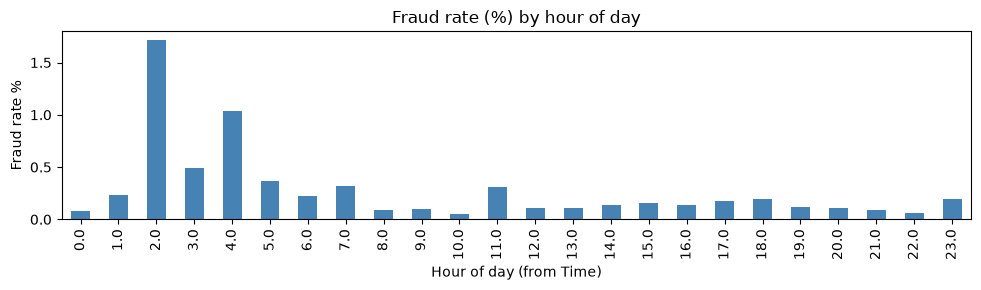

Highest-risk hours:
 hour
2.0    1.713
4.0    1.041
3.0    0.487
Name: Class, dtype: float64


In [3]:
import matplotlib.pyplot as plt
df["hour"] = (df.Time % 86400) // 3600
rate = df.groupby("hour").Class.mean() * 100
ax = rate.plot(kind="bar", figsize=(10, 3), color="steelblue",
               title="Fraud rate (%) by hour of day")
ax.set_xlabel("Hour of day (from Time)"); ax.set_ylabel("Fraud rate %")
plt.tight_layout()
plt.savefig("../reports/figures/fraud_by_hour.png", dpi=150)
plt.show()
print("Highest-risk hours:\n", rate.sort_values(ascending=False).head(3).round(3))